Course: Pattern recognition \\
Date: 22/2/21 \\
Task: KNN classification of hand-written digits \\
Test set: hand-writeen digits in black and white \\
Train set: hand-written digits in black and white \\


In [ ]:
#basic python libraries
import csv
import time
import scipy
import numpy as np
! pip install --upgrade scipy
import matplotlib.pyplot as plt
from collections import Counter
from scipy.spatial import cKDTree
from sklearn.neighbors import KDTree, BallTree, DistanceMetric


In [ ]:
#intialize file pathes
train_path="/content/drive/MyDrive/Google colab/train.csv"
test_path = "/content/drive/MyDrive/Google colab/test.csv"
condensed_train_path = "/content/drive/MyDrive/Google colab/new_img_train.csv"

In [ ]:
# Manhatan distance: (calculates Manhatan distance between pairwise pixels)
# input values: two images
# return values: distance
def Manhattan_dist(img1, img2):
  return np.mean(np.abs(img1[1:]-img2[1:]))

In [ ]:
#euclidean distance: (calculates Euclidean distance pairwise)
# input values: two images
# return values: distance
def euclidean_dist(img1,img2):
  return np.sqrt(np.mean(np.square(np.subtract(img1[1:],img2[1:]))))

In [ ]:
# To choose the distance metric for naiive search
# input values: two images and the distance algorithm
# return values: distance of two images
def calculate_dist(img1,img2,alg):
  if(alg == "Manhattan_dist"):
    return Manhattan_dist(img1,img2)
  elif (alg == "euclidean_dist"):
    return euclidean_dist(img1,img2)

In [ ]:
#Condensing (works only with naive search function)
# input values: training images, search function (only the naive srch), distance algorithm (string: "Mahnhattan","Euclidean")
# return values: decreased training set
def Condensing(img_train,srch_fnc,dist_alg,n_workers):
  R = []
  l_R = []
  R.append(img_train[0])
  img_train.pop(0)
  l_R.append(R[0][0])

  changes = True

  while(changes == True):
    changes = False   
    for img in img_train:
      temp_te = []
      temp_te.append(img)
      if (srch_fnc == naive_srch):
        predicted = prediction(np.array(l_R),srch_fnc(np.array(R),np.array(temp_te),1,alg),1)
      elif (srch_fnc == optimized_srch):
        predicted = srch_fnc(R,temp_te,1,alg)
      if (img[0]!=predicted[0]):
        R.append(img)
        l_R.append(img[0])
        img_train.remove(img)
        changes = True
  return R

In [ ]:
#naiive search:
#Based on the input "dist_alg" computes the distance between two datasets
# input values: array of training images and array of test images
# return values: an array of neighbours of each test image
#retuen value: an array of indexes which shows the index of k nearest neighbours for each data in test dataset
def naive_srch(img_train, img_test, k,dist_alg):
  neighbours = []
  for img_te in img_test:
    dist_vec=[]
    for img_tr in img_train:
      dist_vec.append(calculate_dist(img_tr, img_te,dist_alg))
    dist_vec = np.array(dist_vec)
    neighbours.append(np.argsort(dist_vec)[:k])
  return np.array(neighbours)

In [ ]:
#optimized search using cKDTrees
# Decreases the number of searches to log(N)
# input values: trainig images as a cKDTree, k, the distance algorithm as an integer (1: Manhattan, 2: Eculidean)
# return values: List of neighbors of each training image
def optimized_srch(tree,img_test,k,dist_alg,n_workers):
  neighbours = []
  for img_te in img_test:
    dist,indx = tree.query(img_te , k , p = dist_alg,workers = n_workers)
    neighbours.append(img_train[indx])
  return neighbours

In [ ]:
#Input function: (reads CSV files and returns a 2D vector)
# input values: file_name
# return values: list of images
def input_fnc(file_name):
  file = open(file_name)
  numpy_array = np.loadtxt(file, delimiter=",")
  return numpy_array

In [ ]:
# Predict the label
# input values: the lixt of neighbours and k
# return values: predicted labels
def prediction(neighbours,k):
  predicted = []
  if (k==1):
    predicted = [n[0] for n in neighbours]
  else:
    l_list = [[p[0] for p in n] for n in neighbours]
    predicted = [max(set(l), key = l.count) for l in l_list] 
  return np.array(predicted)

In [ ]:
#calculate the accuracy
# input values: the correct labels for test data set and the predicted labels
# return values: accuracy in percentage
def cal_accuracy(l_test,predicted):
  return (np.sum(l_test == predicted)/len(l_test))*100

In [ ]:
#Processing the train data set. 
img_train = input_fnc(file_name = train_path)
img_test = input_fnc(file_name= test_path )
l_train = [i[0] for i in img_train]
l_test = [i[0] for i in img_test]

In [ ]:
#generating cKDTree of the training images
Start=time.time()
img_train_tree=cKDTree(img_train)
End=time.time()
print("Time to generate the cKDTree: " + str((End-Start)/60))

Time to generate the cKDTree: 5.567415070533753


In [ ]:
#using cKDTrees O(N log N)
accuracy_l = []
Run_time_l = []
for k in [1,3,5,10,15]:
  print("========================================================================================================")
  print("number of neighbours = "+str(k))
  print("========================================================================================================")
  Start =time.time()
  predicted = prediction(neighbours = optimized_srch(tree = img_train_tree, img_test= img_test, k=k, dist_alg = 2,n_workers = -1), k=k)
  End=time.time()
  t = (End-Start)/60
  acc = cal_accuracy(np.array(l_test),np.array(predicted))
  accuracy_l.append(acc)
  Run_time_l.append(t)
  print("running time of KNN alg:" + str(t)+" minutes")
  print("accuracy of classification: " + str(acc)+"\n")

number of neighbours = 1
running time of KNN alg:42.53138851324717 minutes
accuracy of classification: 96.45356976201586

number of neighbours = 3
running time of KNN alg:59.42302404642105 minutes
accuracy of classification: 96.54023065128992

number of neighbours = 5
running time of KNN alg:48.08849962949753 minutes
accuracy of classification: 96.46023598426771

number of neighbours = 10
running time of KNN alg:46.27184383074442 minutes
accuracy of classification: 96.02693153789747

number of neighbours = 15
running time of KNN alg:36.82233422597249 minutes
accuracy of classification: 95.57362842477168



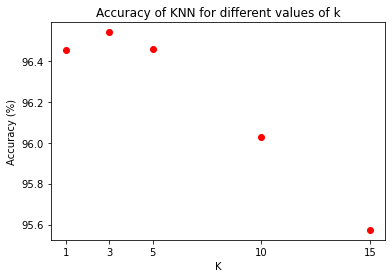

In [3]:
k = [1,3,5,10,15]
accuracy_l = [96.45356976201586 , 96.54023065128992 , 96.46023598426771 , 96.02693153789747 , 95.57362842477168 ]
Run_time_l = [ 44.35870982805888 , 54.47687706549962 , 60.84104852676391 , 48.47458232243856 , 37.17609805266063 ]
plt.title("Accuracy of KNN for different values of k")
plt.plot(k,accuracy_l,'ro')
plt.xlabel("K")
plt.ylabel("Accuracy (%)")
plt.xticks(k)
plt.show
plt.savefig('/content/drive/MyDrive/Google colab/Accuracy.png')

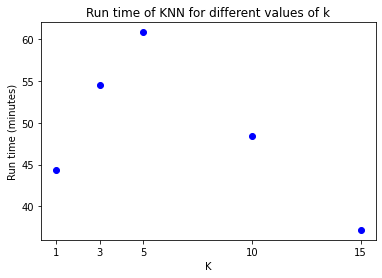

In [4]:
k = [1,3,5,10,15]
run_time = [ 44.35870982805888 , 54.47687706549962 , 60.84104852676391 , 48.47458232243856 , 37.17609805266063 ]
plt.title("Run time of KNN for different values of k")
plt.plot(k,Run_time_l,'bo')
plt.xlabel("K")
plt.ylabel("Run time (minutes)")
plt.xticks(k)
plt.show
plt.savefig('/content/drive/MyDrive/Google colab/Runtime.png')